In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pingouin import intraclass_corr  # For ICC calculation
from scipy.stats import spearmanr, kruskal

In [2]:

# 1. Load data
df = pd.read_csv("evaluations.csv")


# 2. Clean column names
df.columns = df.columns.str.strip()

# 3. Rename columns to short, safe names
rename_dict = {
    "The explanation is clear and easy to understand": "Clarity",
    "The explanation uses appropriate clinical language": "Clinical_Language",
    "The explanation is understandable without technical AI knowledge": "NonTech_Understandable",

    "The explanation is consistent with the visual appearance of the wound": "Visual_Consistency",
    "The explanation aligns with the provided quantitative wound features": "Quant_Feature_Alignment",
    "The explanation does not introduce unsupported or hallucinated information": "No_Hallucination",

    "The explanation helps summarize wound characteristics": "Summarization",
    "The explanation adds value beyond raw numerical outputs": "Adds_Value",
    "The explanation could support documentation or reporting (not decision-making)": "Supports_Documentation",

    "Overall quality of the LLM-generated explanations for this wound": "Overall_Quality",
    "Would you consider these explanations helpful for understanding wound characteristics (not for diagnosis or treatment)?": "Helpful",

    "Wound ID (put here the file number e.g. w1)": "Wound_ID",
    "Professional role": "Professional_Role"
}

df = df.rename(columns=rename_dict)

# 4. Define category columns
interpretability_cols = [
    "Clarity",
    "Clinical_Language",
    "NonTech_Understandable"
]

consistency_cols = [
    "Visual_Consistency",
    "Quant_Feature_Alignment",
    "No_Hallucination"
]

usefulness_cols = [
    "Summarization",
    "Adds_Value",
    "Supports_Documentation"
]

# Ensure numeric
rating_cols = interpretability_cols + consistency_cols + usefulness_cols 
# + [
#     "Overall_Quality", "Helpful"
# ]

df[rating_cols] = df[rating_cols].apply(pd.to_numeric, errors="coerce")


In [3]:
# Columns to clean
cols = ["Professional_Role", "Years of experience in wound care", "Primary clinical setting"]
unique_evaluators = df.drop_duplicates(subset="Username")

role_counts = unique_evaluators["Professional_Role"].value_counts()
print("Number of unique evaluators by role:")
print(role_counts)

Number of unique evaluators by role:
Professional_Role
Physician    6
Nurse        2
Name: count, dtype: int64


In [4]:
role_vs_setting = pd.crosstab(
    unique_evaluators["Professional_Role"],
    unique_evaluators["Primary clinical setting"]
)
print("Unique evaluators by role and clinical setting:")
print(role_vs_setting)


Unique evaluators by role and clinical setting:
Primary clinical setting  Home care  Hospital  Outpatient clinic
Professional_Role                                               
Nurse                             0         1                  1
Physician                         1         5                  0


In [5]:
role_vs_experience = pd.crosstab(
    unique_evaluators["Professional_Role"],
    unique_evaluators["Years of experience in wound care"]
)
print("Unique evaluators by role and experience:")
print(role_vs_experience)


Unique evaluators by role and experience:
Years of experience in wound care  2–5 years  6–10 years  Less than 2 years  \
Professional_Role                                                             
Nurse                                      0           0                  1   
Physician                                  4           1                  1   

Years of experience in wound care  More than 10 years  
Professional_Role                                      
Nurse                                               1  
Physician                                           0  


In [6]:
df["Interpretability_Clarity"] = df[interpretability_cols].mean(axis=1)
df["Consistency_Hallucination"] = df[consistency_cols].mean(axis=1)
df["Usefulness_Interpretation"] = df[usefulness_cols].mean(axis=1)

category_cols = [
    "Interpretability_Clarity",
    "Consistency_Hallucination",
    "Usefulness_Interpretation"
]

print("\nDescriptive statistics per category:")
print(df[category_cols].agg(["mean", "median", "std", "min", "max"]))


Descriptive statistics per category:
        Interpretability_Clarity  Consistency_Hallucination  \
mean                    4.358025                   4.074074   
median                  4.333333                   4.000000   
std                     0.549691                   0.707107   
min                     3.000000                   2.000000   
max                     5.000000                   5.000000   

        Usefulness_Interpretation  
mean                     4.098765  
median                   4.000000  
std                      0.694111  
min                      2.000000  
max                      5.000000  


In [7]:
wound_avg = df.groupby("Wound_ID")[category_cols].mean()
print("\nAverage category scores per wound:")
print(wound_avg)


Average category scores per wound:
          Interpretability_Clarity  Consistency_Hallucination  \
Wound_ID                                                        
W1                        4.380952                   4.476190   
W10                       4.416667                   4.166667   
W2                        4.416667                   4.333333   
W3                        4.500000                   4.041667   
W4                        4.291667                   4.083333   
W5                        4.333333                   3.916667   
W6                        4.222222                   3.962963   
W7                        4.333333                   3.875000   
W8                        4.407407                   4.000000   
W9                        4.291667                   3.958333   

          Usefulness_Interpretation  
Wound_ID                             
W1                         4.333333  
W10                        4.000000  
W2                         4.16

In [8]:
# 8. Inter-rater agreement (ICC)
print("\nInter-rater agreement (ICC):")

for cat in category_cols:
    df_icc = df.pivot_table(
        index="Wound_ID",
        columns="Professional_Role",
        values=cat
    ).reset_index()

    df_long = df_icc.melt(
        id_vars="Wound_ID",
        var_name="Rater",
        value_name="Score"
    ).dropna()

    icc = intraclass_corr(
        data=df_long,
        targets="Wound_ID",
        raters="Rater",
        ratings="Score"
    )

    print(f"\n{cat}")
    print(icc[["Type", "ICC", "CI95%", "pval"]])




Inter-rater agreement (ICC):

Interpretability_Clarity
    Type       ICC          CI95%      pval
0   ICC1 -0.207168   [-0.7, 0.44]  0.730452
1   ICC2 -0.201123  [-0.73, 0.46]  0.725456
2   ICC3 -0.203158  [-0.72, 0.45]  0.725456
3  ICC1k -0.522602  [-4.75, 0.62]  0.730452
4  ICC2k -0.503514  [-5.34, 0.63]  0.725456
5  ICC3k -0.509907  [-5.08, 0.62]  0.725456

Consistency_Hallucination
    Type       ICC          CI95%      pval
0   ICC1  0.215056  [-0.42, 0.72]  0.252552
1   ICC2  0.191109  [-0.52, 0.72]  0.298068
2   ICC3  0.180119  [-0.47, 0.71]  0.298068
3  ICC1k  0.353985  [-1.44, 0.84]  0.252552
4  ICC2k  0.320892  [-2.19, 0.84]  0.298068
5  ICC3k  0.305255   [-1.8, 0.83]  0.298068

Usefulness_Interpretation
    Type       ICC            CI95%      pval
0   ICC1 -0.611801   [-0.88, -0.02]  0.978372
1   ICC2 -0.697928   [-1.04, -0.01]  0.981231
2   ICC3 -0.630542   [-0.89, -0.05]  0.981231
3  ICC1k -3.152000  [-14.69, -0.05]  0.978372
4  ICC2k -4.620939   [51.64, -0.02]  0.98123

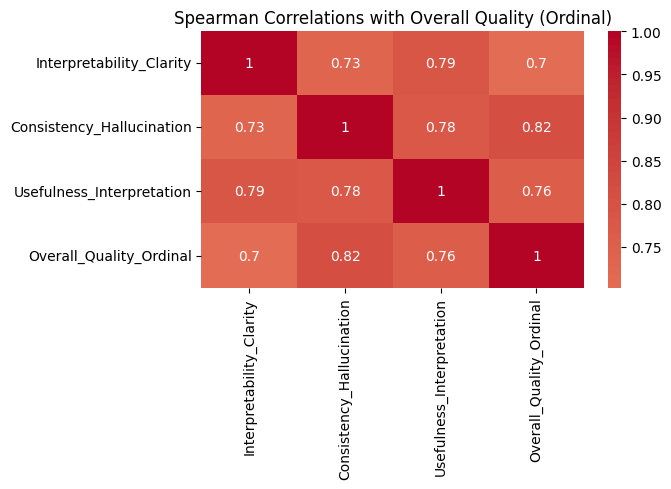

In [9]:
#Correlate with overall_quality
quality_map = {"Poor": 1, "Fair": 2, "Good": 3, "Very good": 4, "Excellent": 5}
df["Overall_Quality_Ordinal"] = df["Overall_Quality"].map(quality_map)

corr_cols = category_cols + ["Overall_Quality_Ordinal"]
corr = df[corr_cols].corr(method="spearman")  # Spearman good for ordinal Likert

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Spearman Correlations with Overall Quality (Ordinal)")
plt.tight_layout()
plt.show()


In [10]:
halluc_mean = df["No_Hallucination"].mean()
halluc_flagged = (df["No_Hallucination"] < 3).mean() * 100

print(f"\nMean hallucination score: {halluc_mean:.2f}")
print(f"Potential hallucination cases (≤3): {halluc_flagged:.1f}%")


Mean hallucination score: 4.36
Potential hallucination cases (≤3): 1.2%


In [11]:
import re
from collections import Counter

comment_col = 'Please describe any unclear, misleading, or hallucinated statements in the LLM-generated explanations, or provide any additional comments on their interpretability and usefulness.(optional)'
comments = (
    df[comment_col]
    .dropna()                    # remove empty comments
    .astype(str)
    .str.lower()
    .str.strip()
)

# Basic text cleaning
def clean_text(text):
    text = re.sub(r"http\S+", "", text)      # remove URLs
    text = re.sub(r"[^a-z\s]", "", text)     # remove punctuation/numbers
    text = re.sub(r"\s+", " ", text)         # normalize spaces
    return text

comments = comments.apply(clean_text)


In [12]:
all_words = " ".join(comments).split()

stopwords = {
    "the","and","to","of","is","are","was","were","for","in","that","this",
    "with","it","as","on","be","by","or","from","at","an"
}

filtered_words = [w for w in all_words if w not in stopwords and len(w) > 2]

word_freq = Counter(filtered_words)

print(word_freq.most_common(15))


[('wound', 4), ('please', 3), ('may', 3), ('also', 2), ('presence', 2), ('hollow', 2), ('discoloration', 2), ('reflect', 2), ('infection', 2), ('tissue', 2), ('based', 2), ('wounds', 2), ('yellow', 2), ('surrounding', 2), ('color', 2)]
